<table style="width:100%; border:3px solid #1F4E79; border-collapse:collapse;">
<tr>
<td style="padding:25px; text-align:center;">

<h1><span style="color:#1F4E79;">M1 Agentic AI & Building AI Agents</span></h1>

<h2>CLIP & LLaVA Laboratory</h2>

<hr style="width:70%;">

<h3>👨‍💻 Prepared by</h3>

<b>MOUADILI Merouane</b><br>
3<sup>nd</sup>-year PhD student

<br><br>

<h3>🏛️ Research team</h3>

<b>DSAI2S Research Team – C3S Laboratory</b><br>
Faculty of Sciences and Techniques of Tangier (FSTT)<br>
Abdelmalek Essaâdi University, Tetouan, Morocco

<br><br>


<h3>👨‍🏫 Thesis supervisor</h3>

<b>Pr. El Mokhtar En-Naimi</b>

</td>
</tr>
</table>

# Part I — LAB STATEMENT

## Exercise 1 — Installation and model loading

### Q1. What is CLIP?

CLIP is a model from OpenAI (2021) that understands images and text together. The idea is simple: it was trained on a huge number of images found online with their captions, around 400 million pairs. During training, it learned to match each image with the right caption. So in the end, if we give it an image and a few sentences, it can tell us which sentence fits the image best. That’s what makes it useful for things like zero-shot classification or searching images with text.

### Q2. What are its two main components?

CLIP is made of two encoders. The first one is the image encoder. In the model we use here, it’s a Vision Transformer (ViT-B/32), which splits the image into small 32×32 patches. The second one is the text encoder, which is a Transformer that reads the sentence. Each encoder gives a vector of size 512. Since both vectors are in the same space, we can compare an image with a text directly, usually with cosine similarity.

### Q3. What is the role of CLIPProcessor?

The processor is the preparation step. We can’t send a raw image or a raw sentence to the model, so the processor does the work for us. For images, it resizes them to 224×224 and normalizes the pixels like during training. For text, it tokenizes the sentence and adds padding so all inputs have the same length. Basically, it makes sure the data is in the format the model expects.

### Q4. What is the role of CLIPModel?

CLIPModel is the actual network with its pretrained weights. It takes what the processor gives it and computes the embeddings of the images and the texts. It can also return the similarity scores between images and texts directly (logits_per_image). In our code, we load it with from_pretrained and send it to the GPU if there is one, otherwise it runs on the CPU.

In [1]:
# Install the libraries needed for the lab (-q = quiet mode, less output)
!pip install -q transformers torch torchvision pillow matplotlib pandas

In [2]:
import torch
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from transformers import CLIPProcessor, CLIPModel

# Use the GPU if there is one otherwise the CPU
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

# Load the pretrained CLIP model and send it to the chosen device
model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)

# Load the processor that prepares images and texts for the model
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

Device: cuda


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

...

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

## Exercise 2 — Load an image

Image size: (550, 550)
Image mode: RGB


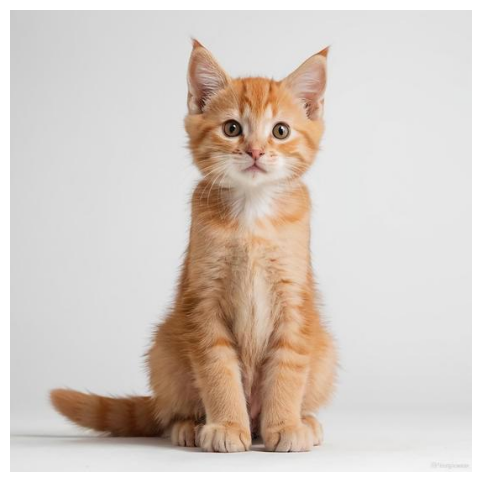

In [3]:
IMAGE_PATH = "/kaggle/input/datasets/mouadilimerouane/cat-image/cat.jpg"

image = Image.open(IMAGE_PATH).convert("RGB")
print("Image size:", image.size)
print("Image mode:", image.mode)

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off");

###  Q5. What is the size of the image?

The image size is (550, 550), so it is 550 pixels wide and 550 pixels high. It’s a square image.

### Q6. What type of data is stored in the PIL image object?

The PIL image object stores the pixels of the picture. Here the mode is RGB, so each pixel has 3 values (red, green, blue), each one an integer between 0 and 255.

## Exercise 3 — Image/Text similarity

In [4]:
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a horse",
    "a photo of a person"
]

inputs = processor(
    text=texts,
    images=image,
    return_tensors="pt",
    padding=True
)
inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    outputs = model(**inputs)

probs = outputs.logits_per_image.softmax(dim=1)[0].cpu()

for text, probability in zip(texts, probs):
    print(f"{text:35s}: {probability.item():.4f}")

a photo of a cat                   : 0.9886
a photo of a dog                   : 0.0064
a photo of a car                   : 0.0001
a photo of a horse                 : 0.0006
a photo of a person                : 0.0044


### Q7. Which description has the highest probability?
The description with the highest probability is “a photo of a cat”, with 0.9886, so almost 99%. All the other descriptions are very low: “a photo of a dog” gets 0.0064, “a photo of a person” 0.0044, “a photo of a horse” 0.0006 and “a photo of a car” only 0.0001.

### Q8. Is it compatible with the actual image?
Yes, the result matches the image, because the picture shows a cat. CLIP is very confident here, almost 99%. It’s also interesting that the second choice is “a photo of a dog” even if its probability is very small (only 0.0064, less than 1%). This makes sense, because a dog is also a pet animal and visually closer to a cat than a car or a horse. The car gets the lowest score, which is logical since it’s a very different kind of object.

### Q9. Why can CLIP compare an image with a sentence?
Because CLIP puts images and texts in the same space. The image encoder turns the picture into a vector, and the text encoder turns the sentence into a vector of the same size (512 here). During training, CLIP learned to bring an image and its correct caption close to each other, and to keep wrong pairs far apart. So after training, we can measure how close an image and a sentence are, using cosine similarity. A high similarity means the sentence describes the image well.

### Q10. What does softmax() do?
The raw scores returned by CLIP (logits_per_image) are not easy to read, they are just numbers like 25 or 18. softmax() turns these scores into probabilities. All the values become positive and between 0 and 1, and they add up to 1. The highest score gets the highest probability. This way we can read the result as “the model thinks there is X% chance that this description fits the image”. We use dim=1 because we want the probabilities across the 5 texts for our image.

## Exercise 4 — Zero-shot classification

In [7]:
def classify_image(image, classes):
    # Turn each class name into a sentence, like in Exercise 3
    texts = [f"a photo of a {c}" for c in classes]

    # Prepare the image and the texts for CLIP
    inputs = processor(text=texts, images=image, return_tensors="pt", padding=True)
    inputs = {k: v.to(device) for k, v in inputs.items()}

    # Get the scores and convert them to probabilities
    with torch.no_grad():
        outputs = model(**inputs)
    probs = outputs.logits_per_image.softmax(dim=1)[0].cpu()

    # Keep the class with the highest probability
    best = probs.argmax().item()
    return classes[best], probs[best].item()

classes = ["cat", "dog", "car", "airplane", "horse", "bird"]

prediction, probability = classify_image(image, classes)
print("Prediction:", prediction)
print("Probability:", probability)

Prediction: cat
Probability: 0.9925347566604614


### Q11. What is zero-shot classification?
Zero-shot classification means classifying an image into categories that the model was never specifically trained on. With CLIP, we just write the possible classes as sentences, like “a photo of a cat” or “a photo of a dog”, and the model picks the one that matches the image best. In my test, with the classes cat, dog, car, airplane, horse and bird, CLIP predicted cat with a probability of about 0.99, without any training on these classes.

### Q12. Why is it not necessary to train a new classifier?
Because CLIP already learned a general link between images and text during its pretraining on millions of image–caption pairs. It already “knows” what a cat, a car or a bird looks like and how they are described in words. So instead of training a new model with labeled data, we only change the list of text descriptions. If we want new classes, we just add new sentences. This saves a lot of time and we don’t need a labeled dataset.

### Q13. What happens if the correct class is not included in the candidate classes?

CLIP can only choose among the classes we give it. If the correct class is missing, it will still pick one of them, the one that is the “least wrong”, and it can even give it a high probability. This is because softmax always forces the probabilities to add up to 1, so the model never says “none of these”. For example, when I removed “cat” from the list, the prediction became dog with a probability of 0.857. The model is quite confident, even though the answer is wrong. This shows a limit of zero-shot classification: the result depends on the list of classes we choose.

In [6]:
# Test without the correct class
classes_without_cat = ["dog", "car", "airplane", "horse", "bird"]

prediction, probability = classify_image(image, classes_without_cat)
print("Prediction:", prediction)
print("Probability:", probability)

Prediction: dog
Probability: 0.8567175269126892


### Exercise 5 — Evaluate CLIP

In [8]:
import os
for root, dirs, files in os.walk("/kaggle/input"):
    if "cat1.jpg" in files:
        print(root)

/kaggle/input/datasets/mouadilimerouane/images


In [9]:
import os

BASE_PATH = "/kaggle/input/datasets/mouadilimerouane/images"

dataset = [
    ("cat1.jpg", "cat"),
    ("cat2.jpg", "cat"),
    ("dog1.jpg", "dog"),
    ("dog2.jpg", "dog"),
    ("car1.jpg", "car"),
    ("car2.jpg", "car"),
    ("airplane1.jpg", "airplane"),
    ("airplane2.jpg", "airplane"),
    ("horse1.jpg", "horse"),
    ("horse2.jpg", "horse"),
    ("bird1.jpg", "bird"),
    ("bird2.jpg", "bird"),
]

classes = ["cat", "dog", "car", "airplane", "horse", "bird"]

records = []
for filename, actual in dataset:
    img = Image.open(os.path.join(BASE_PATH, filename)).convert("RGB")
    predicted, prob = classify_image(img, classes)
    records.append({
        "image": filename,
        "actual": actual,
        "predicted": predicted,
        "probability": round(prob, 4),
        "correct": predicted == actual
    })

results_df = pd.DataFrame(records)
print(results_df)

# Accuracy = number of correct predictions / total number of images
accuracy = results_df["correct"].sum() / len(results_df)
print(f"\nAccuracy: {accuracy:.2%}")

# Show the wrong predictions
print("\nIncorrectly classified images:")
print(results_df[~results_df["correct"]])

            image    actual predicted  probability  correct
0        cat1.jpg       cat       cat       0.9942     True
1        cat2.jpg       cat       cat       0.9925     True
2        dog1.jpg       dog       dog       0.9970     True
3        dog2.jpg       dog       dog       0.9970     True
4        car1.jpg       car       car       0.9916     True
5        car2.jpg       car       car       0.9922     True
6   airplane1.jpg  airplane  airplane       0.9974     True
7   airplane2.jpg  airplane  airplane       0.9934     True
8      horse1.jpg     horse     horse       0.9997     True
9      horse2.jpg     horse     horse       0.9997     True
10      bird1.jpg      bird      bird       0.9954     True
11      bird2.jpg      bird      bird       0.9978     True

Accuracy: 100.00%

Incorrectly classified images:
Empty DataFrame
Columns: [image, actual, predicted, probability, correct]
Index: []


### Q14. What is the obtained accuracy?
I tested CLIP on 12 labeled images (2 per class: cat, dog, car, airplane, horse, bird). All 12 were correctly classified, so the accuracy is 12 / 12 = 100%. The model was also very confident, with probabilities between 0.9916 and 0.9997 for every image.

### Q15. Which images are incorrectly classified?
In my test, no image was incorrectly classified. The table of wrong predictions is empty. I think this is because my images are clear photos where the object is well visible and centered, and the six classes are very different from each other.

### Q16. Give at least two possible reasons for the errors.
Even if I had no errors here, CLIP can make mistakes in other cases. Some possible reasons:

Similar classes, Image quality or content ,The text prompt, or missing class

## Exercise 6 — Prompt engineering with CLIP

In [10]:
prompts = [
    "a cat",
    "a photo of a cat",
    "a photograph showing a cat",
    "an image containing a cat",
    "a domestic animal called a cat"
]

# Prepare the cat image and all the prompts
inputs = processor(text=prompts, images=image, return_tensors="pt", padding=True)
inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    outputs = model(**inputs)

# Raw similarity scores 
scores = outputs.logits_per_image[0].cpu()
# Probabilities across the 5 prompts
probs = scores.softmax(dim=0)

prompt_df = pd.DataFrame({
    "prompt": prompts,
    "score": scores.numpy().round(2),
    "probability": probs.numpy().round(4)
}).sort_values("score", ascending=False)

print(prompt_df)

                           prompt      score  probability
2      a photograph showing a cat  28.299999       0.4024
1                a photo of a cat  27.980000       0.2932
4  a domestic animal called a cat  27.190001       0.1325
3       an image containing a cat  27.129999       0.1247
0                           a cat  26.160000       0.0473


### Q17. Are the scores identical?
No, the scores are not identical, even if all the prompts describe the same thing: a cat. The scores go from 26.16 for “a cat” to 28.30 for “a photograph showing a cat”. The difference looks small in raw scores (about 2 points), but after softmax it becomes much bigger: from 0.0473 to 0.4024. So the way we write the sentence changes how CLIP matches it with the image.

### Q18. Which prompt gives the highest score?
The highest score is for “a photograph showing a cat”, with a score of 28.30 and a probability of 0.4024. It is followed by “a photo of a cat” (27.98). The lowest one is the simple prompt “a cat” (26.16), which gets less than 5% of the probability.

### Q19. What does this demonstrate about prompt formulation?
This shows that the way we write the prompt changes CLIP results. The prompts that mention a photo got the best scores, and the short prompt “a cat” got the lowest one. I think this is because CLIP learned from image captions on the internet, and these captions are usually full sentences. So it’s better to write complete descriptions and to test a few prompts to find the best one. This is called prompt engineering.

# Part B — CLIP Image Retrieval

## Exercise 7 — Build an image database

In [3]:
# Exercise 7 — Build an image database
import os

IMAGE_DIR = "/kaggle/input/datasets/mouadilimerouane/images-part2"

def to_tensor(features):
    if hasattr(features, "pooler_output"):
        return features.pooler_output
    return features

# List all images in the folder
image_files = sorted([f for f in os.listdir(IMAGE_DIR)
                      if f.lower().endswith((".jpg", ".jpeg", ".png"))])
print("Number of images:", len(image_files))

# Compute and store a normalized embedding for each image
image_embeddings = []
for f in image_files:
    img = Image.open(os.path.join(IMAGE_DIR, f)).convert("RGB")
    inputs = processor(images=img, return_tensors="pt")
    inputs = {k: v.to(device) for k, v in inputs.items()}
    with torch.no_grad():
        emb = to_tensor(model.get_image_features(**inputs))
    emb = emb / emb.norm(dim=-1, keepdim=True)   # normalize (length = 1)
    image_embeddings.append(emb.cpu())

image_embeddings = torch.cat(image_embeddings)   # shape: (N, 512)
print("Embeddings shape:", image_embeddings.shape)

Number of images: 22
Embeddings shape: torch.Size([22, 512])


## Exercise 8 — Text-to-image retrieval

Number of images: 22
Embeddings shape: torch.Size([22, 512])

Top-5 images for: "a person playing football"
1. football2.jpg  ->  0.2957
2. ball1.jpg  ->  0.2852
3. football1.jpg  ->  0.2557
4. tennis1.jpg  ->  0.2381
5. horse2.jpg  ->  0.2299


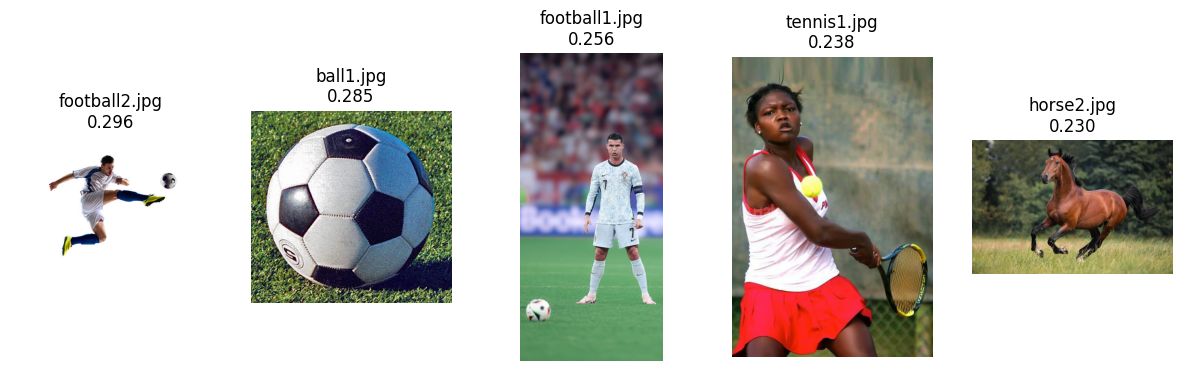

In [10]:
import os

QUERY = "a person playing football"

# 1. Compute the normalized embedding of the query
text_inputs = processor(text=[QUERY], return_tensors="pt", padding=True)
text_inputs = {k: v.to(device) for k, v in text_inputs.items()}
with torch.no_grad():
    text_emb = to_tensor(model.get_text_features(**text_inputs))
text_emb = (text_emb / text_emb.norm(dim=-1, keepdim=True)).cpu()

# 2. Cosine similarity = dot product, since both are normalized
similarities = (image_embeddings @ text_emb.T).squeeze(1)

# 3. Top-5 most similar images
top5 = similarities.topk(5)
print(f'\nTop-5 images for: "{QUERY}"')
for rank, (score, idx) in enumerate(zip(top5.values, top5.indices), start=1):
    print(f"{rank}. {image_files[idx.item()]}  ->  {score.item():.4f}")

# Display the Top-5 images
plt.figure(figsize=(15, 4))
for i, (score, idx) in enumerate(zip(top5.values, top5.indices)):
    plt.subplot(1, 5, i + 1)
    plt.imshow(Image.open(os.path.join(IMAGE_DIR, image_files[idx.item()])).convert("RGB"))
    plt.title(f"{image_files[idx.item()]}\n{score.item():.3f}")
    plt.axis("off")
plt.show()

### Q20. What is the most similar image?
The most similar image is football2.jpg, with a cosine similarity of 0.2957. The full Top-5 is: football2.jpg (0.2957), ball1.jpg (0.2852), football1.jpg (0.2557), tennis1.jpg (0.2381) and horse2.jpg (0.2299). The scores are quite close to each other, which is normal with CLIP, because cosine similarities between images and texts usually stay between 0.2 and 0.35.

### Q21. Is it semantically relevant?
Yes, the first result is relevant, because football2.jpg shows a football match with players. The second one, ball1.jpg, is only a football without any person. It is related to the topic, but it doesn’t really match “a person playing”. It even scored higher than football1.jpg, which shows a person playing football. So CLIP seems to give a lot of weight to the word “football” and to the ball itself. Then tennis1.jpg comes 4th, which makes sense because it’s also a person doing a sport with the ball. horse2.jpg in 5th place is less logical. Maybe the green grass in the picture looks like a football field. Overall, the results are good but not perfect: CLIP understands the general idea (sport, ball, field) better than the exact meaning of the sentence.

### Q22. Why does this method not require image labels?
Because we don’t compare the query with labels, we compare it directly with the content of the images. CLIP turns each image and the text query into vectors in the same space, and then we only measure how close they are. The images in the folder have no class or tag, just a file name that the model never uses. So we can search in any collection of images with a free sentence, without labeling anything by hand.

### Q23. Give one real-world application of semantic image retrieval.
One example is searching in a photo gallery, like on a phone. We can type “my dog in the snow” and get the right pictures, even if we never added tags to them. Another example is e-commerce: a customer can describe a product in words, like “red running shoes”, and the website shows the most similar product images.

# Part C — LLaVA

## Exercise 9 — Architecture

### complete
Image
  |
  v
CLIP Vision Encoder
  |
  v
Projection Layer (MLP)
  |
  v
Language Model
  |
  v
Text Response

### Q24. What is the role of the vision encoder?
The vision encoder is the part that “looks” at the image. In LLaVA, it is the image encoder of CLIP (a Vision Transformer). It cuts the image into small patches and turns each patch into a vector. These vectors describe what is in the image: objects, colors, shapes, and so on. The vision encoder is already pretrained and usually stays frozen, so it is not changed during LLaVA’s training.

### Q25. Why is a projection layer required?
Because the vision encoder and the language model don’t speak the same “language”. The vectors produced by CLIP don’t have the same size or meaning as the word embeddings the LLM uses. The projection layer converts the image features into vectors that the language model can read, like extra words in the input. We call them visual tokens.Without this step, the LLM would not be able to understand the image features.

### Q26. What is the role of the language model?

The language model is the part that understands the question and writes the answer. It receives the visual tokens from the projection layer together with the text of the user’s question. Then it generates the response word by word, like a chatbot. In LLaVA, it is an open-source LLM like Vicuna (based on LLaMA). Thanks to it, the model can describe an image, answer questions about it and keep a conversation, which CLIP alone cannot do.

## Exercise 10 — Run LLaVA

In [4]:
# STUDENT TASK
from transformers import AutoProcessor, LlavaForConditionalGeneration

MODEL_ID = "llava-hf/llava-1.5-7b-hf"

processor_llava = AutoProcessor.from_pretrained(MODEL_ID)
llava = LlavaForConditionalGeneration.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,   # half precision to save GPU memory
    device_map="auto"            # spread the model on the available GPUs
)
print("LLaVA loaded")

processor_config.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/701 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/674 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/505 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/950 [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/686 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/141 [00:00<?, ?B/s]

LLaVA loaded


In [7]:
def ask_llava(image, question, max_new_tokens=200):
    # LLaVA 1.5 prompt format: the <image> tag marks where the image goes
    prompt = f"USER: <image>\n{question} ASSISTANT:"
    inputs = processor_llava(images=image, text=prompt, return_tensors="pt").to(llava.device, torch.float16)

    with torch.no_grad():
        output = llava.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)

    # Keep only the generated answer 
    new_tokens = output[0][inputs["input_ids"].shape[1]:]
    return processor_llava.decode(new_tokens, skip_special_tokens=True).strip()

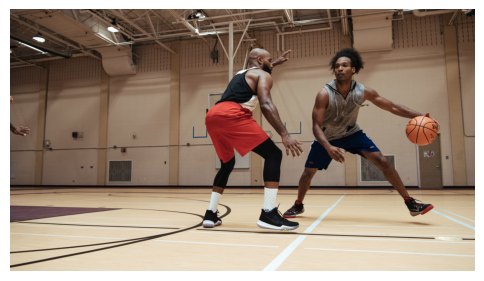

Q: What is happening in this image?
A: In the image, two men are playing basketball on a court. They are both wearing red shorts and are actively engaged in the game.

Q: How many people are visible?
A: There are two people visible in the image.

Q: What objects can you identify?
A: In the image, you can identify a basketball court, two men playing basketball, and a sports ball. The court is surrounded by a white line, and the players are actively engaged in the game. The presence of the sports ball and the players' positions on the court suggest that they are playing a game of basketball.

Q: Describe the image in detail.
A: The image features a basketball court with two men playing a game of basketball. One man is positioned closer to the left side of the court, while the other is on the right side. Both players are actively engaged in the game, with one of them holding a basketball.

There are several other people in the scene, some of whom are standing or walking around the court, 

In [14]:
llava_image = Image.open(os.path.join(IMAGE_DIR, "basketball1.jpg")).convert("RGB")

plt.figure(figsize=(6, 6))
plt.imshow(llava_image)
plt.axis("off")
plt.show()

questions = [
    "What is happening in this image?",
    "How many people are visible?",
    "What objects can you identify?",
    "Describe the image in detail."
]

answers = []
for q in questions:
    a = ask_llava(llava_image, q)
    answers.append({"question": q, "answer": a})
    print(f"Q: {q}\nA: {a}\n")

llava_df = pd.DataFrame(answers)   # record the answers

# Exercise 11 — Visual Question Answering

In [8]:
vqa_images = ["basketball1.jpg", "football2.jpg", "food1.jpg", "building1.jpg", "cat1.jpg"]

vqa_questions = [
    ("counting", "How many people are visible?"),
    ("objects",  "What objects can you see?"),
    ("location", "Where was this photo taken?"),
    ("action",   "What is happening in this image?"),
    ("text",     "Is there any text or number visible? If yes, what does it say?"),
]

vqa_records = []
for img_name in vqa_images:
    img = Image.open(os.path.join(IMAGE_DIR, img_name)).convert("RGB")
    for q_type, q in vqa_questions:
        answer = ask_llava(img, q, max_new_tokens=80)
        vqa_records.append({
            "Image": img_name,
            "Type": q_type,
            "Question": q,
            "LLaVA Answer": answer
        })
        print(f"[{img_name}] {q}\n -> {answer}\n")

vqa_df = pd.DataFrame(vqa_records)

[basketball1.jpg] How many people are visible?
 -> There are two people visible in the image.

[basketball1.jpg] What objects can you see?
 -> In the image, you can see a basketball court, a basketball, and two men playing basketball.

[basketball1.jpg] Where was this photo taken?
 -> This photo was taken in a gym.

[basketball1.jpg] What is happening in this image?
 -> In the image, two men are playing basketball on a court. They are both wearing red shorts and are actively engaged in the game.

[basketball1.jpg] Is there any text or number visible? If yes, what does it say?
 -> Yes, there is a number visible in the image. The number is 23, which is likely the basketball court number.

[football2.jpg] How many people are visible?
 -> There is only one person visible in the image.

[football2.jpg] What objects can you see?
 -> In the image, you can see a soccer player, a soccer ball, and a pair of blue and white socks.

[football2.jpg] Where was this photo taken?
 -> This photo was tak

In [14]:
# Human evaluation: 1 = correct, 0 = wrong (checked by looking at each image)
human_eval = [
    1, 1, 1, 0, 0,   # basketball1.jpg  (only one in red shorts, no number 23)
    1, 1, 1, 1, 0,   # football2.jpg    (no number 10)
    1, 0, 0, 0, 0,   # food1.jpg        (no knife, kitchen not visible, no cutting board, no 12)
    1, 0, 1, 1, 0,   # building1.jpg    (no truck, no 100)
    1, 1, 1, 1, 1,   # cat1.jpg
]

vqa_df["Human Evaluation"] = ["Correct" if e == 1 else "Wrong" for e in human_eval]
display(vqa_df[["Image", "Question", "LLaVA Answer", "Human Evaluation"]])

# VQA accuracy = correct answers / total questions
vqa_accuracy = sum(human_eval) / len(human_eval)
print(f"\nVQA Accuracy: {sum(human_eval)}/{len(human_eval)} = {vqa_accuracy:.2%}")

# Accuracy per type of question (useful for Q28)
vqa_df["score"] = human_eval
print("\nAccuracy per question type:")
print(vqa_df.groupby("Type")["score"].mean().map("{:.0%}".format))

,Image,Question,LLaVA Answer,Human Evaluation
0,basketball1.jpg,How many people are visible?,There are two people visible in the image.,Correct
1,basketball1.jpg,What objects can you see?,"In the image, you can see a basketball court, ...",Correct
2,basketball1.jpg,Where was this photo taken?,This photo was taken in a gym.,Correct
3,basketball1.jpg,What is happening in this image?,"In the image, two men are playing basketball o...",Wrong
4,basketball1.jpg,"Is there any text or number visible? If yes, w...","Yes, there is a number visible in the image. T...",Wrong
5,football2.jpg,How many people are visible?,There is only one person visible in the image.,Correct
6,football2.jpg,What objects can you see?,"In the image, you can see a soccer player, a s...",Correct
7,football2.jpg,Where was this photo taken?,This photo was taken in a soccer field.,Correct
8,football2.jpg,What is happening in this image?,"In the image, a soccer player is kicking a soc...",Correct
9,football2.jpg,"Is there any text or number visible? If yes, w...","Yes, there is a number visible in the image. T...",Wrong



VQA Accuracy: 16/25 = 64.00%

Accuracy per question type:
Type
action       60%
counting    100%
location     80%
objects      60%
text         20%
Name: score, dtype: object


### Q27. What is the VQA accuracy?
I asked 5 questions on 5 images, so 25 questions in total. After checking each answer myself, 16 were correct, so the VQA accuracy is 16 / 25 = 64%. The results depend a lot on the image: LLaVA got all 5 answers right on the cat image, but only 1 out of 5 on the pizza image.

### Q28. Which types of questions are difficult for LLaVA?
The hardest questions were about text and numbers (only 20% correct). For 4 images out of 5, LLaVA said there was a number (23, 10, 12, 100) when there was none. It seems to answer “yes” and invent a plausible detail instead of saying “no”.

Questions about objects and actions were also difficult (60%). The model sometimes added things that were not in the image, like a truck next to the building. It also said that both basketball players wore red shorts, but only one did.


On the other hand, counting people worked very well (100%), and it also recognized correctly when there were no people. So LLaVA understands the general idea of the image well, but it often adds small details that are not really there.

## Exercise 12 — Hallucination

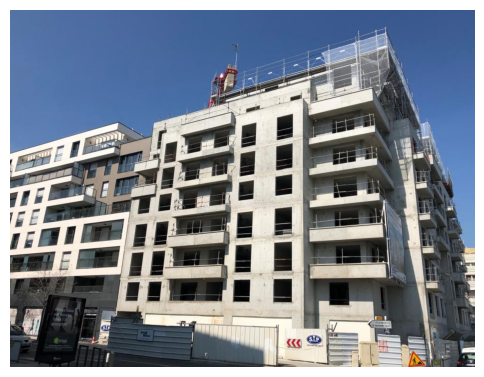

Q: Is there a bicycle in this image?
A: No, there is no bicycle in this image. The image features a large building under construction, with scaffolding and a crane.

Q: What color is the bicycle?
A: The bicycle is blue.

Q: Where is the bicycle located?
A: The bicycle is located in front of a building, possibly in a parking area or a designated bike parking area.



In [15]:
hallu_image = Image.open(os.path.join(IMAGE_DIR, "building1.jpg")).convert("RGB")

plt.figure(figsize=(6, 6))
plt.imshow(hallu_image)
plt.axis("off")
plt.show()

hallu_questions = [
    "Is there a bicycle in this image?",
    "What color is the bicycle?",
    "Where is the bicycle located?"
]

hallu_records = []
for q in hallu_questions:
    a = ask_llava(hallu_image, q, max_new_tokens=80)
    hallu_records.append({"Question": q, "LLaVA Answer": a})
    print(f"Q: {q}\nA: {a}\n")

hallu_df = pd.DataFrame(hallu_records)

### Q29. Does the bicycle actually exist?
No, there is no bicycle in building1.jpg. The image only shows a building under construction with scaffolding and a crane. LLaVA even confirmed it with the first question

### Q30. Did LLaVA invent information?
Yes. With the first question, LLaVA correctly said there was no bicycle. But when I asked “What color is the bicycle?”, it answered that the bicycle is blue. Then, for “Where is the bicycle located?”, it said it was in front of the building, maybe in a parking area. Both answers are completely invented.

### Q31. What is a visual hallucination?
A visual hallucination is when the model describes something that is not in the image. It can invent an object, a color, a number or a detail and say it with confidence, as if it were really there. In this exercise, LLaVA first said there was no bicycle in my building image, but then described it as blue and parked in front of the building.

### Q32. Why can a multimodal model hallucinate?
There are several reasons:

-The language model is very strong: LLaVA is built on an LLM that learned which words usually go together. It can write what is likely in this kind of scene (a bicycle in a city, a knife with a pizza) instead of what is really in the image.

-The vision part loses details: the image is reduced to a small size (336×336 for LLaVA 1.5) and turned into visual tokens, so some details can be lost.

-Leading questions: a question like “What color is the bicycle?” already suggests that a bicycle exists. The model tends to follow the question instead of contradicting it.

# Part D — CLIP vs LLaVA

## Exercise 13 — Comparative experiment

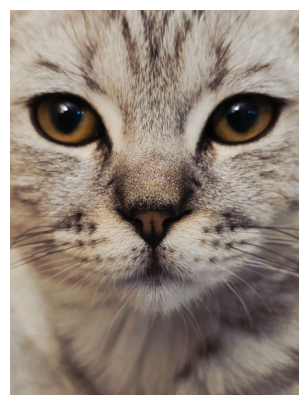

CLIP results:
  a photo of a cat    : 0.9953
  a photo of a dog    : 0.0039
  a photo of a horse  : 0.0008

LLaVA answer:
  A cat is present in the image. It has a white and gray color pattern, and it is looking directly at the camera.


In [16]:
comp_image = Image.open(os.path.join(IMAGE_DIR, "cat1.jpg")).convert("RGB")

plt.figure(figsize=(5, 5))
plt.imshow(comp_image)
plt.axis("off")
plt.show()

# --- CLIP ---
clip_texts = ["a photo of a cat", "a photo of a dog", "a photo of a horse"]
inputs = processor(text=clip_texts, images=comp_image, return_tensors="pt", padding=True)
inputs = {k: v.to(device) for k, v in inputs.items()}
with torch.no_grad():
    outputs = model(**inputs)
clip_probs = outputs.logits_per_image.softmax(dim=1)[0].cpu()

print("CLIP results:")
for t, p in zip(clip_texts, clip_probs):
    print(f"  {t:20s}: {p.item():.4f}")

# --- LLaVA ---
llava_question = "What animal is present in the image? Describe its appearance."
llava_answer = ask_llava(comp_image, llava_question, max_new_tokens=150)
print("\nLLaVA answer:")
print(" ", llava_answer)

### Q33. Which model is better suited to image classification?
CLIP is better for image classification. We just give it the list of classes and it returns a probability for each one. On cat1.jpg, it gave 0.9953 for “a photo of a cat”, against 0.0039 for the dog and 0.0008 for the horse, so the result is clear and easy to measure. It is also much faster and lighter than LLaVA, and in Exercise 5 it reached 100% accuracy on my 12 images. LLaVA also found the cat, but its answer is free text, so we have to read it to extract the class, and it can add invented details.

### Q34. Which model is better for image description?
LLaVA is better for image description, because it can generate text. For the same image, it said: “A cat is present in the image. It has a white and gray color pattern, and it is looking directly at the camera.” CLIP cannot do this: it only told us that “a photo of a cat” was the best sentence among the three we gave it.

In [17]:
comparison = pd.DataFrame({
    "Property": ["Input", "Main output", "Zero-shot classification", "Image retrieval",
                 "Text generation", "VQA", "Open-ended response"],
    "CLIP": ["An image and a list of candidate texts",
             "Similarity scores / probabilities for each text",
             "Yes, it's its main use",
             "Yes, by comparing embeddings",
             "No, it can only choose among given texts",
             "No, or only by choosing among fixed answers",
             "No"],
    "LLaVA": ["An image and a free question (prompt)",
              "A text answer written by the model",
              "Possible, but less direct and slower",
              "No, it does not produce embeddings to compare",
              "Yes",
              "Yes",
              "Yes"]
})
display(comparison)

,Property,CLIP,LLaVA
0,Input,An image and a list of candidate texts,An image and a free question (prompt)
1,Main output,Similarity scores / probabilities for each text,A text answer written by the model
2,Zero-shot classification,"Yes, it's its main use","Possible, but less direct and slower"
3,Image retrieval,"Yes, by comparing embeddings","No, it does not produce embeddings to compare"
4,Text generation,"No, it can only choose among given texts",Yes
5,VQA,"No, or only by choosing among fixed answers",Yes
6,Open-ended response,No,Yes


# Final Mini-Project

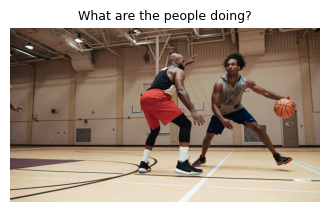

Answer: The people are playing basketball on a court. 



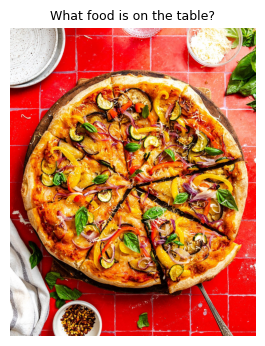

Answer: Pizza 



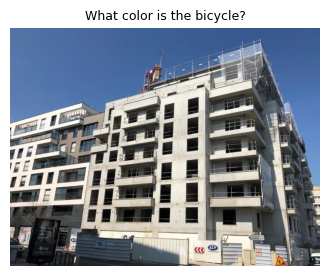

Answer: Blue 



'Blue'

In [18]:
def image_assistant(image_path, question, show=True):
    """Receive an image and a question, return LLaVA's answer."""
    img = Image.open(image_path).convert("RGB")

    # Small instruction to reduce hallucinations 
    prompt = (question + " Answer only with what you can actually see in the image. "
              "If something is not visible, say that it is not there.")
    answer = ask_llava(img, prompt, max_new_tokens=150)

    if show:
        plt.figure(figsize=(4, 4))
        plt.imshow(img)
        plt.axis("off")
        plt.title(question, fontsize=9)
        plt.show()
        print("Answer:", answer, "\n")
    return answer

# Try the assistant on a few examples
image_assistant(os.path.join(IMAGE_DIR, "basketball1.jpg"), "What are the people doing?")
image_assistant(os.path.join(IMAGE_DIR, "food1.jpg"), "What food is on the table?")
image_assistant(os.path.join(IMAGE_DIR, "building1.jpg"), "What color is the bicycle?")

The assistant works well on normal questions: it described the basketball game and recognized the pizza. But even with an extra instruction asking it to say when something is not visible, it still answered “Blue” for the bicycle that does not exist. A simple instruction in the prompt is not enough to stop hallucinations caused by a leading question.

# Conclusion 
In this lab, we worked with two vision-language models, CLIP and LLaVA, and we tested what each one can and cannot do.

CLIP

First, we loaded CLIP and used it to compare an image with several sentences. With my cat image, CLIP gave almost 99% to “a photo of a cat”, so it recognized the image very easily. Then we used it for zero-shot classification. Without any training, it classified my 12 test images correctly, which gave an accuracy of 100%. This result is very good, but my images were clear photos and the six classes were very different from each other, so the task was quite easy. With harder images, like drawings or similar animals, the accuracy would probably be lower.

We also saw two limits of CLIP. First, it always picks one of the classes we give it. When I removed “cat” from the list, it predicted “dog” with 86% confidence, even though the answer was wrong. Second, the way we write the prompt matters. For the same image, “a photograph showing a cat” got a better score than just “a cat”. So it’s better to write full sentences that look like real captions.

For image retrieval, CLIP found the most relevant image for “a person playing football” among 22 images, without using any labels. But the ranking was not perfect: an image of a ball with no person came second, and a horse image appeared in the Top-5. CLIP understands the general topic (football, sport, grass) better than the exact meaning of the sentence.

LLaVA

LLaVA works differently. It uses the vision encoder of CLIP, a projection layer and a language model, so it can write answers instead of just comparing texts. It was much heavier than CLIP, and we needed the GPU to run it in a reasonable time.

In the VQA exercise, LLaVA reached an accuracy of 64% (16 out of 25). It was very good at counting people (100%) but very bad with text and numbers (20%). It often said that there was a number in the image when there was none. It also added objects that did not exist, like a knife next to the pizza or a truck near the building.

The bicycle test showed this problem clearly. LLaVA first said there was no bicycle in the image, but when I asked about its color, it answered “blue” and even said where it was parked. The question already suggested that a bicycle existed, and the model followed it instead of checking the image. This is a visual hallucination, and it shows that we can’t trust LLaVA’s answers without checking them.

Comparison and final assistant

When we used the same cat image with both models, both found the cat. CLIP gave a clear probability (0.9953), while LLaVA gave a description with the colors and the pose of the cat. So CLIP is better for classification and retrieval: it’s fast, light and easy to evaluate. LLaVA is better for description and answering questions, but it’s slower and can invent details.


To sum up, CLIP and LLaVA are not competitors but complementary tools. CLIP is good at matching images and text, and LLaVA is good at talking about images. Both work without training on our own data, which is impressive. But both have limits: CLIP depends on the classes and prompts we choose, and LLaVA can hallucinate. In a real application, it would be important to check the results and not trust the model blindly.